# Gradient forest: *P. guttatus*

Fit SNP-specific forests using the example VCF, sample coordinates and 19 bioclim rasters, then map environmental turnover.


## Install pyGF

The `pyGF` package is only available in my github repo, so the installation will need to be
'by hand'.

* Open a new terminal and `cd ~` to go to your home directory
* `git clone https://github.com/isaacovercast/pygf.git` to pull down this repository
* `pip install -e pygf` to install this package and all requirements
* Restart the kernel for this notebook w/ the 'circle arrow' button in the notebook toolbar
* Now you should be able to do the imports in the next cell

In [1]:
from pathlib import Path
# Python's build-in pathlib module for working with file and folder paths

import numpy as np
# NumPy is the standard library for fast numerical calculations and handling multi-dimensional arrays
import pandas as pd
# pandas is the primary library for creating and manipulating spreadsheet-style data tables (DataFrames)
import matplotlib.pyplot as plt
# Matplotlib's plotting module which powers maps and charts

from pygf import GradientForest, read_coordinates, read_vcf, sample_environment
# pulls four specific tools from pygf which is a Python package built for Gradient Forest in landscape genomics
# GradientForest is the machine learning model class used to find nonlinear relationships between 
# environmental gradients (like temperature or rainfall) and genetic variation across space
# read_coordinates is the helper function to load sample latitudes and longitudes
# sample_environment is teh helper function used to extract climate data from raster files at sample locations

## Read samples and genotypes

`read_coordinates` returns a GeoDataFrame from the headerless sample, longitude, latitude file. `read_vcf` returns an xarray Dataset of alternate-allele dosages (0, 1, 2), with missing calls as NaN.

Keep SNPs with call rate ≥ 80% and minor allele frequency ≥ 5%, then sample 256 across the file. `one_per_contig=True` keeps one eligible SNP per RAD contig; use `False` for whole-chromosome data. Set `max_variants=None` to keep all eligible SNPs. Plain and gzipped VCFs are supported.

`samples=sites` returns genotypes in coordinate-file order. Climate rows preserve the same order, so `sites`, `X` and `y` stay aligned.

<Axes: >

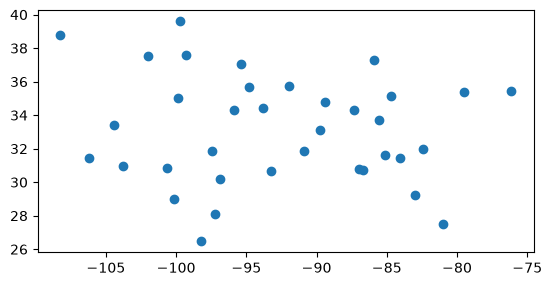

In [2]:
sites = read_coordinates("/home/jovyan/shared/EasternSnakeGenetics/Pguttatus_coords.txt")
genotypes = read_vcf(
    "/home/jovyan/shared/EasternSnakeGenetics/Pguttatus.vcf", 
    # opens a variant call format which stores DNA sequence variations across different individuals
    samples=sites,
    # filters the genetic dataset to keep only the individuals listed in sites variable
    min_call_rate=0.8,
    # removes low-quality genetic markers by requiring that at least 80% of the samples have valid, non-missing data for a 
    # given variant
    min_maf=0.05,
    # sets a minor allele frequency threshold of 5% which removes vey rare genetic variants that appear in fewer than 5% 
    # of the sampled chromosomes
    one_per_contig=True,
    # keeps only one genetic variant per contig (a continuous stretch of assembled DNA) which prevents closely linked variants 
    # from skewing downstreams populations
    max_variants=256,
    # randomly downsamples the remaining passing variants so the final dataset contains at most 256 markers
    random_state=42,
    # sets a fixed seed for the random number generator
)
sites.plot()
# calls a built-in plotting method on the sites object to generate a visual map showing where the snake sample were collected but no map

## Sample climate

`sample_environment` takes the bioclim directory, opens a bounding box around the sites with 20% of its width/height added on each side, and extracts native-resolution values in coordinate-file order. It reprojects sites to the raster CRS and closes the rasters after sampling. Use `variables=["bio1", "bio12"]` to select layers or `buffer=0.1` for a smaller region.

Missing climate values remain NaN. `drop_missing=True` removes incomplete rows; if used, align the other inputs to those remaining IDs once before fitting. The example retains all 36 sites.

In [3]:
X = sample_environment("/home/jovyan/shared/bioclim", sites)
# takes sites (geographic coordinates) and looks up the local environmental conditions at each exact spot from the spatial files 
# stored in the bioclim folder
y = genotypes.dosage.to_pandas()
# pulls the allele dosage values from the filtered genetic data, dosage represents the count of alternate alleles an individual 
# carries at each genetic marker (0, 1, or 2 copies for a diploid)
X.head()
# displays the first five rows of the environmental data table

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
LSU99213,19.115833,11.865000,40.417633,676.937683,33.139999,3.784,29.355999,11.547334,15.234667,27.132000,10.488000,1478.0,158.0,92.0,14.483758,418.0,320.0,366.0,405.0
OMNH9224,15.792167,15.137000,37.766968,913.650269,35.743999,-4.336,40.079998,20.497334,4.397333,26.977333,4.397333,626.0,104.0,17.0,52.633015,247.0,62.0,198.0,62.0
OMNH8361,15.129333,12.856667,37.627800,792.639038,32.000000,-2.168,34.167999,14.956667,5.099333,24.677999,5.099333,1509.0,169.0,86.0,19.535410,470.0,323.0,337.0,323.0
FLMNH153506,18.062166,13.024334,41.315613,711.381104,33.180000,1.656,31.524000,10.619333,23.122667,26.576666,9.070666,1488.0,162.0,88.0,20.799999,443.0,273.0,307.0,430.0
FLMNH151609,15.625667,17.631334,44.424850,837.177002,35.023998,-4.664,39.688000,25.017332,7.156667,25.798000,5.204000,332.0,62.0,8.0,66.924088,162.0,27.0,151.0,32.0


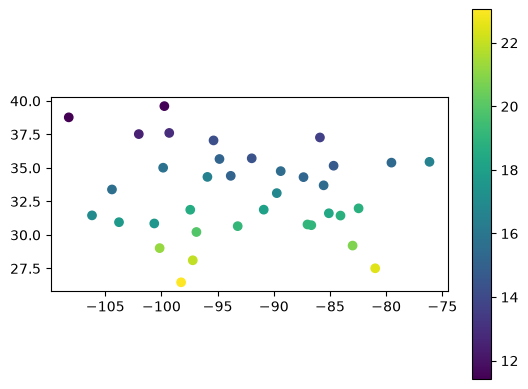

In [4]:
sites.plot(column=X.bio1, legend=True);

## Fit and inspect

Each SNP uses its observed genotypes. Only responses with positive out-of-bag (OOB) R² and permutation importance contribute to turnover.

`max_level=2` uses approximate conditional permutations for correlated predictors; `max_level=0` gives marginal permutations. `corr_threshold` sets the correlation cutoff. Other options control tree size (`max_features`, `min_samples_leaf`, `max_depth`), curve resolution (`n_bins`), permutation repeats (`n_permutations`), minimum skill (`min_oob_r2`), density correction (`density_correction`) and tree parallelism (`n_jobs`).

In [5]:
gf = GradientForest(
    n_estimators=100, max_level=2, random_state=42, keep_response_curves=True,
    # n_estimators=100 builds a random forest of 100 decision trees for every individual genetic markers in y (256 forests in total here)
    # max_level=2 controls how predictor importance is calculated when climate variables are correlated with each other, setting this to 2 
    # uses a conditional permutation grid up to 2 tree levels deep, preventing correlated climate variables from artificially inflating 
    # each other's importance scores
    # keep_response_curves=True tells the model to save teh individual turnover curves for each SNP rather than discarding them after 
    # averaging which allows us to inspect or plot single SNPs later
).fit(X, y)
# trains the forets using environmental data (x) to predict genetic data (y)
gf.response_scores_.sort_values("oob_r2", ascending=False).head()
# gf. stores the trained model and all its calculated results inside the gf variable
# gf.response_scores_ accesses a summary table generated by the model containing performance metrics for every SNP, including sample 
# coverage and whether teh SNP was kept or skipped
# .sort_values("oob_r2", ascending=False) sorts the summary table from highest to lowest based on oob_r2 (out of bag r2) which measures
# how accurately the climate variables predict a SNP's genotype on samples left out during tree training, higher positive values means a stronger
# link to the enivornment

# this code trains a gradient forest machine learning model on climate (x) and gnetic (y) data and then displays the top 5 genetic markers 
# (SNPs) that are best predicted by the environment


,n_observed,oob_r2,oob_coverage,retained,reason
response,,,,,
RAD_11467:26:C:A,33,0.817141,1.0,True,retained
RAD_49550:52:C:T,30,0.780227,1.0,True,retained
RAD_44571:22:A:G,30,0.756812,1.0,True,retained
RAD_42610:36:G:T,29,0.742778,1.0,True,retained
RAD_18759:57:T:C,31,0.732192,1.0,True,retained


`response_scores_` records OOB skill and inclusion for every SNP; `oob_predictions_` holds its OOB predictions. `permutation_importances_` contains raw MSE increases and `response_importances_` contains allocated R². Set `keep_forests=True` to retain fitted trees in `forests_`.

`importance_` ranks predictors by mean allocated R²; `feature_importances_` contains the same values in input order.

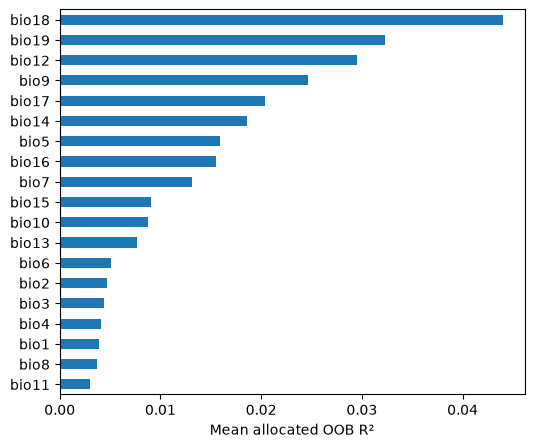

In [6]:
gf.importance_.sort_values().plot.barh(figsize=(6, 5), xlabel="Mean allocated OOB R²");
# gf.importance accesses teh models calcualted importance scores for every environmental predictor (bio1 through bio19) and
# represents the average out of bag r2 allocated to each climate variable across all contributing SNPS
# .sort_values() sorts importance scores in ascending order,  this ensures the most important climate variables appears at the top
# plot.barh tells panfas/Matplotlib to draw a horizontal bar chart
# ; In Jupyter, adding a semicolon at the end of a plotting command suppresses extra text output so only a clean chart is displayed

## Turnover curves and transformed samples

`turnover_` contains a cumulative curve for each predictor. Steep sections indicate rapid turnover; endpoints give predictor importance. `transform` returns these turnover coordinates, preserving sample IDs. `predict` is an alias; `fit_transform(X, y)` combines fitting and transformation.

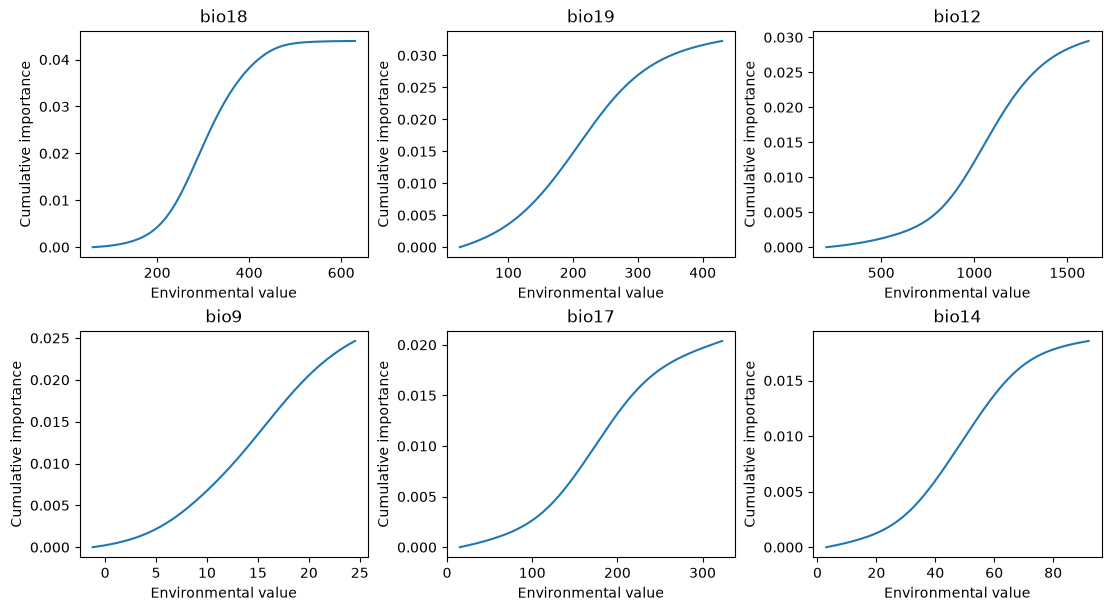

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
# plt.subplots creates a single figure containg a grid of 2 rows and 3 columns (6 individual subplot boxes total)
# figsize sets the overall canvas size to 11 inches wide by 6 inches tall
# layout="constrained" automatically adjusts the spacing between the 6 subplots so that axis titles and tick numbers do not overlap
# fig, axes saves the overall figure container in fig and the 2x3 array of individual plot boxes in axes
for ax, name in zip(axes.flat, gf.importance_.head(6).index):
    # axes.flat flattens the 2x3 grid of subplot boxes into a simple 1D list of 8 boxes
    # gf.importance_.head(6).index takes the 6 rows of gf.importance which is already sorted from higher to lowest and grabs their variable names
    # zip pairs each subplot box (ax) with its corresponding climate variable name (name) for each step of the loop
    curve = gf.turnover_[name]
    # curve = gf.turnover_[name] looks up the calcualted turnover table for the current climate variable (name), which contains
    # raw climate measruremnts (value) and cumulative importance scores (cumulative_importance)
    ax.plot(curve.value, curve.cumulative_importance)
    # ax.plot() draws a line graph inside thec current subplot box (ax), plotting the environmental gradient along the x-axis and
    # cumulative genetic change along the y-axis
    ax.set(title=name, xlabel="Environmental value", ylabel="Cumulative importance")
    # ax.set() sets the subplot's header title to the variable's name and adds descriptive labels to both axes
plt.show()
# renders and displays teh completed 6-panel figure

# this code creates a 2x3 grid of line plots showing the cumulative genetic turnover curves for the top 6 most important climate variables,
# sateep jumps in these curves highlight critical enviornmental thresholds where snake genotypes change most rapdily

In [8]:
turnover = gf.transform(X)
# gf.transform(x) = passes each snake's raw climate measurements (x) through the cumulative turnover curves stored inside the trianed gf model and 
# instead of showing raw units, each value is replaced by its corresponding cumulative importance score at that climate level
turnover.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
LSU99213,0.001192,0.000255,0.003208,0.000997,0.004935,0.003737,0.001119,0.000740,0.013844,0.002585,0.001675,0.028036,0.006532,0.018558,0.000000,0.012415,0.020291,0.033995,0.031751
OMNH9224,0.000460,0.003694,0.002432,0.003277,0.014760,0.001308,0.012559,0.002371,0.001814,0.002382,0.000660,0.002243,0.002262,0.000946,0.008034,0.002230,0.001066,0.004087,0.001414
OMNH8361,0.000379,0.000807,0.002378,0.001948,0.001496,0.002087,0.005761,0.001431,0.002236,0.000462,0.000753,0.028439,0.006946,0.018243,0.001003,0.014165,0.020379,0.029243,0.028561
FLMNH153506,0.000852,0.000922,0.003399,0.001277,0.005090,0.003180,0.002473,0.000560,0.023630,0.001951,0.001359,0.028172,0.006699,0.018359,0.001292,0.013379,0.018704,0.023228,0.032269
FLMNH151609,0.000439,0.004648,0.003923,0.002390,0.012758,0.001185,0.012393,0.003232,0.003816,0.001280,0.000767,0.000390,0.000274,0.000275,0.008721,0.000473,0.000227,0.001447,0.000231


## Map turnover

`plot_turnover()` uses the directory and sites remembered from `sample_environment`, opens the same buffered region, transforms it, and overlays the sites. It defaults to the most important predictor; pass a name such as `"bio1"` to choose another. Directory maps use every fourth cell by default (`stride=1` keeps native resolution).

The result exposes `.figure`, `.ax` and a computed xarray `.turnover` Dataset for export. `transform_raster` remains available for custom xarray grids; missing pixels are masked and values outside training ranges are clamped.

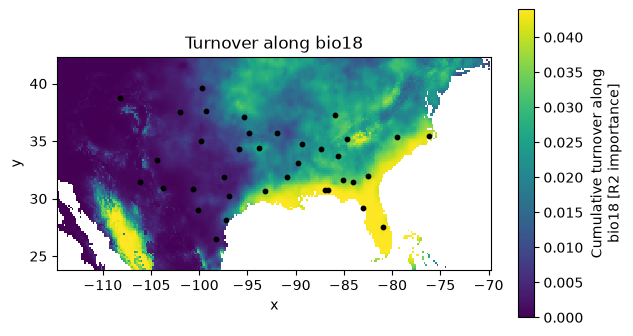

In [9]:
turnover_map = gf.plot_turnover()  # Or gf.plot_turnover("bio1")
# gf.plot_turnover() calls the model's built-in spatial mapping method

## Spatial turnover and environmental biplots

The map and biplot share colours from the first three PCs of GF-transformed environments. Pass the bioclim directory; site bounds, the 20% buffer and downsampling are handled internally. PCA uses the resulting region without standardizing predictors, so GF importance weights are preserved. Labelled arrows show the largest environmental covariance loadings in PC1/2: direction indicates increasing values and relative length indicates contribution to the displayed pattern.

`response=None` uses all contributing SNPs. Pass a SNP name for its own turnover curves (requires `keep_response_curves=True` when fitting). `n_vectors` controls labelled arrows; `label_sites=True` adds sample IDs; `inset=True` places the biplot inside the map. Omit `environment` for a PCA of sample locations alone.

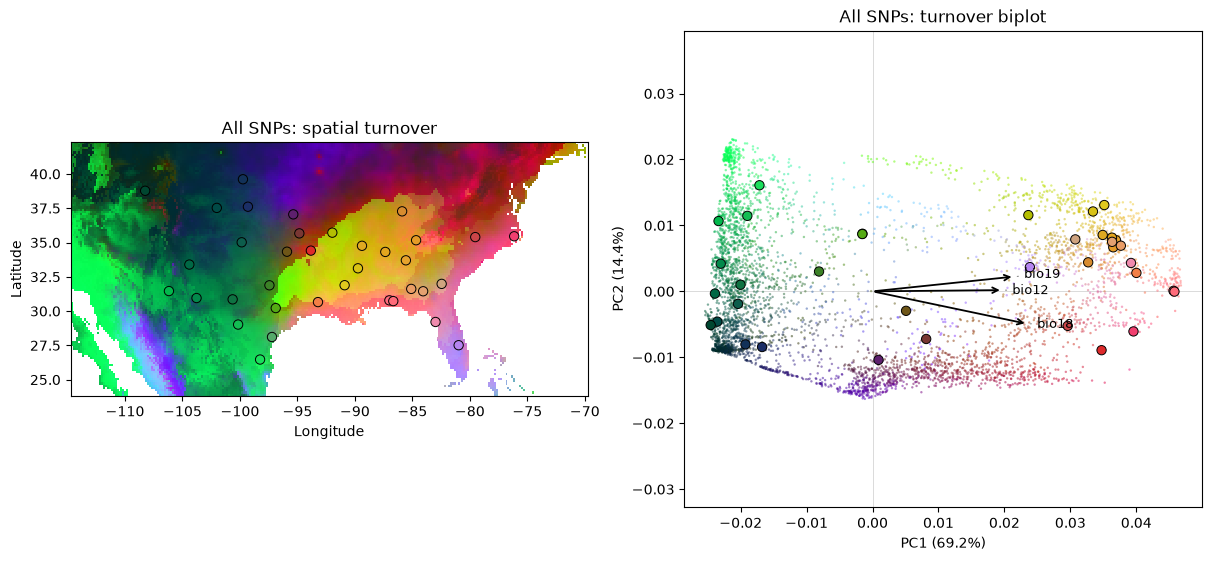

In [16]:
biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", n_vectors=3)
# gf.plot_biplot() calls the model's ordination pltting function which takes the transformed turnover values across all climate variables and compresses them into three
# principle components (pc1, pc2, and pc3)
# x and sites passes your environmental table (x) and sample locations (sites) so the function can plot the exact snake collection sites as points over the landscape
# and inside the PCA ordination space
# n_vectors=3. draws and labels the top 3 climate arrows on the PCA biplot, the direction and length of each arrow show which climate gradients drive teh strongest patterns
# of genetic variation across the PC1 and Pc2 axes

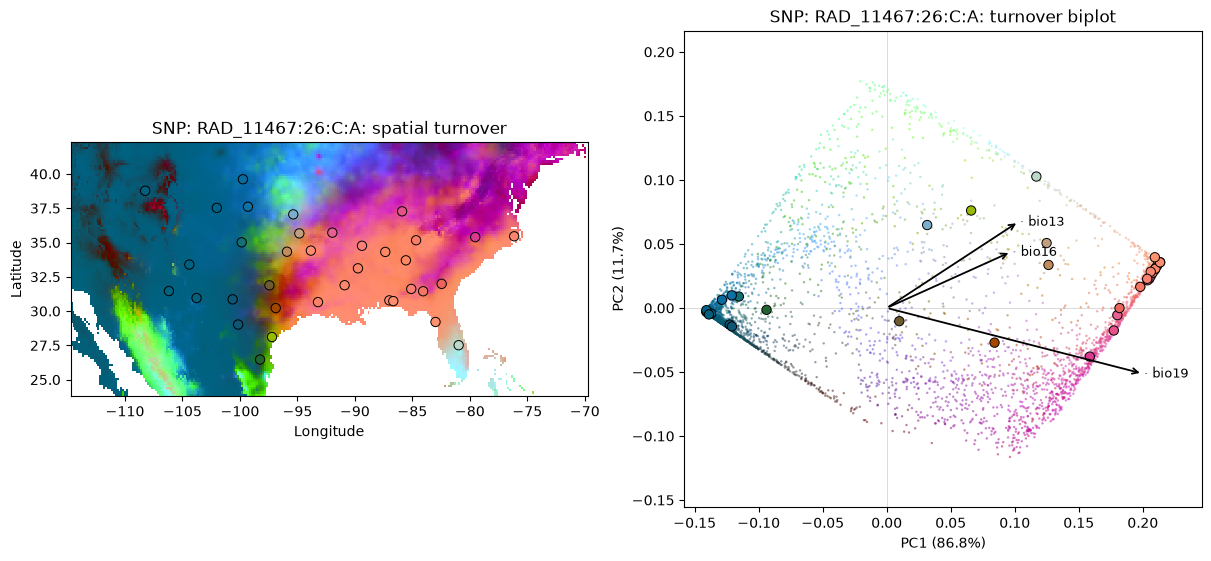

In [20]:
snp = gf.response_scores_.oob_r2.idxmax()
# gf.response_scores_.oob_r2 grabs the out of bag r2 score colummn for every SNP in the model
# .idmax() finds the row with the highest r2 score and returns its index name (the specific ID of that top SNP)
# snp. saves the winning SNP ID into a variable named snp
snp_biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", response=snp, n_vectors=3)

`biplot.scores`, `.vectors` and `.colors` contain the numerical results; `.rgb` is the georeferenced map colour array. Each SNP has its own PCA/colour scale. These plots summarize predicted turnover, not predicted allele frequencies. This example uses individuals; for population-level composition, fit population allele frequencies against population-level environments and supply population locations.

## Export

Save diagnostics, sample coordinates, curves and a GeoTIFF with one named band per predictor.

In [21]:
Path("outputs").mkdir(exist_ok=True)
gf.response_scores_.to_csv("outputs/snp_oob_scores.csv")
gf.importance_.to_csv("outputs/predictor_importance.csv")
turnover.to_csv("outputs/sample_turnover.csv")
pd.concat(gf.turnover_, names=["predictor", "bin"]).to_csv("outputs/turnover_curves.csv")
# path("outputs").mkdir(exist_ok=True) creates a new directory named outputs in current working folder
# gf.response_scores_.to_csv() exports the table of out of bag r2 scores and sample coverage for every SNP to a spreadsheet (snp_oob_scores.csv)
# gf.importance_.to_csv() exports the ranked importance score for each climate predictor to predictor_importance.csv
# turnover_to.csv() exports your transformed turnover values for each individual snake sample to sample_turnover.csv
# pd.concat(gf.turnover_, names=["predictor", "bin"]).tocsv() combines the separate cumulative turnover curves for all 19 climate variables into a 
# single master table (indexed by predictor name and bin number) and saves it as turnover_curves.csv

bands = turnover_map.turnover.to_array("band").rio.write_nodata(np.nan)
bands.attrs["long_name"] = tuple(X.columns)
bands.rio.to_raster("outputs/genomic_turnover.tif", compress="deflate", dtype="float32")
# turnover_map.turnover.to_array("band") stacks the separate trunover map layers for every climate variable into a single multi-band spatial array
# rio.write_nodata(np.nan) marks empty pixels as NaN (NoData) so GIS software renders them transparently
# bands.attrs["long_name"] = tuple(X.colunms) embeds the climate variable names into the file metadata so each map stay properly labeled
# bands.rio.to_raster() saves the multi-band spatial dataset as a standard GeoTIFF (genomic_turnover.tif) using lossless compression (compress="deflate")
# and 32 bit decimal precision (dtype="float32") to keep file sizes small

turnover_map.figure.savefig("outputs/turnover_map.png", dpi=150, bbox_inches="tight")
biplot.figure.savefig("outputs/turnover_biplot.png", dpi=150, bbox_inches="tight")
snp_biplot.figure.savefig("outputs/snp_biplot.png", dpi=150, bbox_inches="tight")
# figure.safvefig() exports each of the three map figures as PNG images inside the outputs folder
# dpi=150 sets the iamge resolution to 150 dots per inch
# bbox_inches="tight" trims away exess white margin around the edges of the figure so axis labels and colorbars are not cut off

The entire point of this exercise was to discover how local climate shapes teh DNA of Eastern corn snakes across their range and to map where their genetics change the most across the landscape. 

Step 1: Gathering the raw ingredients (sites, genotypes, X, y)
Sites gave methe GPS pins for each snake, genotypes -> gave me the DNA table (256 genetic markers for each snake), sample_environment -> used the GPS pins to look up the local weather (19 temperature and rainfaill variables) for each snake. Step 1 gave us a predictor table (x, climate) and a response table (y, DNA). 

Step 2: Finding patterns with machine learning (gf = GradientForet(...).fit(X, y))
Step 2 is when we fed both the predictor table and response table into the gradient forest model. This model built hundreds of decision treest o test whether certain climate conditions reliably predict specific genetic vartiaents. The trained gf objects now holds two key discoveries: which climate variables matter most (gf.importance_) and the exact weather thresholds where DNA changes rapdily (gf.turnover_).

Step 3: Translating weather into genetic change (turnover = gf.transform(X))
Raw weather numbers are hard to compare directly (like 5 C of temperature vs. 200 mm of rain). Using curves learned in step 2, gf.transorm() converted raw weatehr numbers into a single, unified measurement: cumulative genetic turnover. Instead of looking at a map of temperature or rainfall, I now have a mathematical ruler that measures how much snake DNA is expected to change from one climate to another.

Step 4: Painting the big picture (plot_turnover and plot_biplot)
Since we only had DNA samples froma  handful of specific spots, we need to now fill in the blanks across the entire region. plot_turnover() took the single most important cilimate map and colored every pixel by its predicted genetic turnover. plot_biplot() combined all 19 climate variables at once using PCA, turning the top three genetic patterns into red, green, and blue color channels. This sturned abstract spreadsheet numbers into a visual map genetic neighborhoods, shwoing where snake populations are genetically similar (mathicng colors) and where sharp environmetnal boundaries divide them (color shifts).


These are individual genotype responses, not population allele frequencies. OOB skill and turnover alone do not establish adaptation or spatial transfer accuracy. Conditional permutations and smoothing differ from R gradientForest; see the [README](../README.md) for method details and [Ellis et al. (2012)](https://doi.org/10.1890/11-0252.1) for the original method.